<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/3_4_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!sudo apt-get update && sudo apt-get install -y libopencv-dev

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0

In [ ]:
%%writefile gorev4_ortalama_filtre.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <algorithm>

// 3x3 Ortalama Filtresinin Konvolüsyon ile Manuel Gerçeklenmesi
cv::Mat manuelOrtalamaFiltre(const cv::Mat& src) {
    int rows = src.rows;
    int cols = src.cols;
    cv::Mat dst = src.clone();

    // Resmin tüm piksellerini gez
    for (int r = 0; r < rows; ++r) {
        for (int c = 0; c < cols; ++c) {
            int toplam = 0;

            // 3x3 konvolüsyon çekirdeği (komşu 9 piksel)
            for (int kr = -1; kr <= 1; ++kr) {
                for (int kc = -1; kc <= 1; ++kc) {
                    // Kenar taşmalarını engellemek için sınır pikselleri sınırlama (clamping)
                    int nr = std::max(0, std::min(rows - 1, r + kr));
                    int nc = std::max(0, std::min(cols - 1, c + kc));

                    toplam += src.at<uchar>(nr, nc);
                }
            }

            // 9 pikselin aritmetik ortalamasını ata
            dst.at<uchar>(r, c) = (uchar)(toplam / 9);
        }
    }
    return dst;
}

int main() {
    // 1. Resmi tek kanallı (gri) olarak aç
    cv::Mat img = cv::imread("Image1.jpeg", cv::IMREAD_GRAYSCALE);
    if (img.empty()) {
        std::cout << "Hata: 'Image1.jpeg' bulunamadi! Sol panele yuklediginizden emin olun." << std::endl;
        return -1;
    }

    // 2. Manuel konvolüsyon filtresini uygula
    cv::Mat sonuc_manuel = manuelOrtalamaFiltre(img);

    // 3. Karşılaştırma ve doğrulama için hazır OpenCV fonksiyonu
    cv::Mat sonuc_opencv;
    cv::blur(img, sonuc_opencv, cv::Size(3, 3));

    // 4. Çıktıları kaydet
    cv::imwrite("orijinal_gurultulu.jpg", img);
    cv::imwrite("filtreli_manuel.jpg", sonuc_manuel);
    cv::imwrite("filtreli_opencv.jpg", sonuc_opencv);

    std::cout << "Gorev 4 basariyla tamamlandi!" << std::endl;
    std::cout << "- 'filtreli_manuel.jpg' olusturuldu." << std::endl;
    std::cout << "- 'filtreli_opencv.jpg' olusturuldu." << std::endl;

    return 0;
}

Overwriting gorev4_ortalama_filtre.cpp


In [ ]:
!g++ gorev4_ortalama_filtre.cpp -o gorev4_ortalama_filtre `pkg-config --cflags --libs opencv4`
!./gorev4_ortalama_filtre

Gorev 4 basariyla tamamlandi!
- 'filtreli_manuel.jpg' olusturuldu.
- 'filtreli_opencv.jpg' olusturuldu.


--- 1. Orijinal Gürültülü Görüntü ---


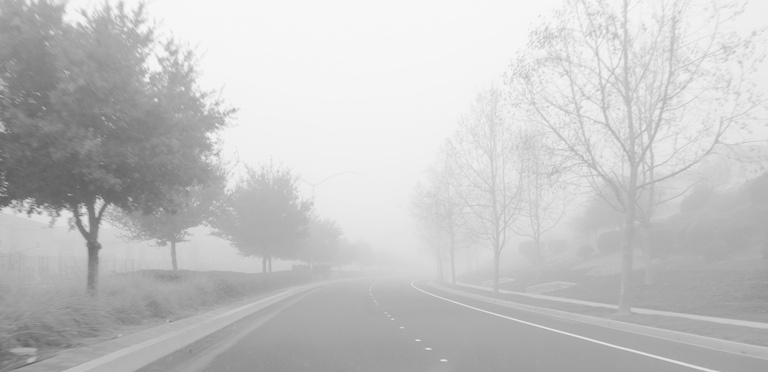


--- 2. Sıfırdan Kodlanan 3x3 Ortalama Filtresi (Manuel) ---


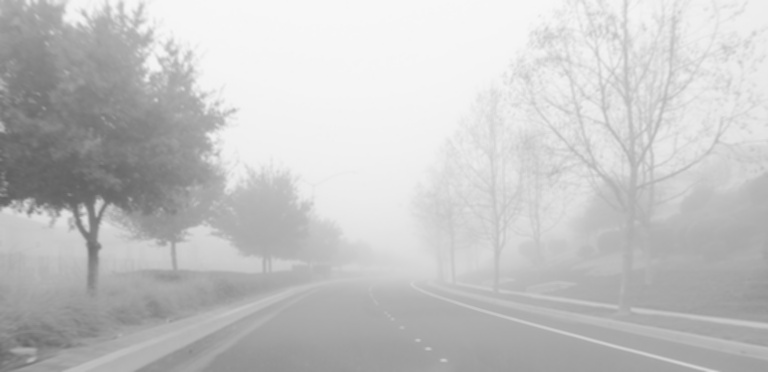


--- 3. OpenCV Hazır Blur Çıktısı (Doğrulama) ---


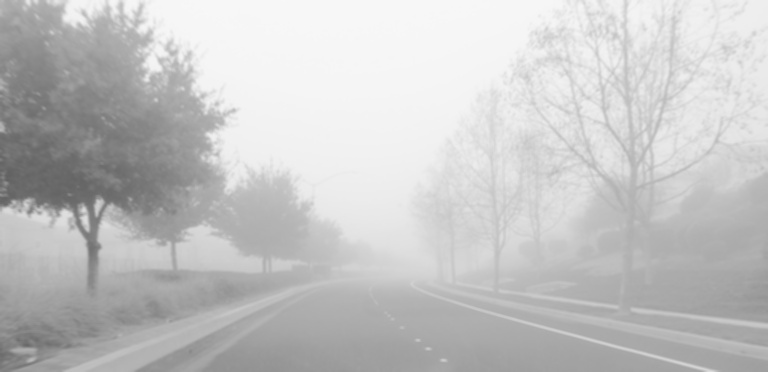

In [ ]:
from IPython.display import Image, display

print("--- 1. Orijinal Gürültülü Görüntü ---")
display(Image('orijinal_gurultulu.jpg'))

print("\n--- 2. Sıfırdan Kodlanan 3x3 Ortalama Filtresi (Manuel) ---")
display(Image('filtreli_manuel.jpg'))

print("\n--- 3. OpenCV Hazır Blur Çıktısı (Doğrulama) ---")
display(Image('filtreli_opencv.jpg'))